# Improving person and shadow removal masks

Run this notebook yourself from top to bottom. All mask construction and inference functions are included below; it does not call external helper scripts.

We compare **original**, **complete people/group**, and **people plus shadow** masks while holding pretrained weights, prompts, seeds and sampling settings fixed. This is inference/pipeline tuning, not weight fine-tuning. The supplied polygons cover the three specific development examples and are not an automatic detector. Shadows are approximate edit regions, not ground-truth segmentations. The model may still create objects, seams or incorrect structures.

The original notebook remains unchanged. The ZIP includes input photos and original masks. If you use this notebook alone, its data cell downloads the official Penn-Fudan archive.

## 0. Fix the notebook environment (run this cell first)

The shared Anaconda Python 3.13 kernel can fail while importing the optional `kernels` package through Transformers, with `Unsupported type for field import_name: str | None`. This happens before model loading. The setup below creates a separate Python **3.12** environment with pinned Diffusers/Transformers/Hub versions; it does not uninstall or change packages in your current environment.

1. Run **only the setup cell below**. Internet access is needed the first time; installation can take several minutes.
2. In VS Code, click the kernel name at the top right → **Select Another Kernel → Jupyter Kernel → DSC180 mask refinement (Python 3.12)**. Refresh the kernel list or reopen the notebook if necessary.
3. Restart the selected kernel, then run the notebook from the top. The setup cell will now just check imports.

If Conda is not found, run these commands in your Anaconda terminal instead, then select the registered kernel:

```bash
conda create -n dsc180-mask-runtime python=3.12 pip -y
conda run -n dsc180-mask-runtime python -m pip install "torch>=2.6,<3" "diffusers==0.35.1" "transformers==4.57.1" "huggingface-hub==0.36.2" "accelerate>=1,<2" "numpy>=1.26,<3" Pillow requests safetensors ipykernel ipywidgets
conda run -n dsc180-mask-runtime python -m ipykernel install --user --name dsc180-mask-runtime --display-name "DSC180 mask refinement (Python 3.12)"
```

This notebook refines masks at inference time; it does not update pretrained model weights.


In [1]:
# Run this cell alone first, then select the registered kernel before Run All.
import os, sys, shutil, subprocess
from pathlib import Path
os.environ.update(USE_TF="0", USE_FLAX="0", USE_TORCH="1")
KERNEL_NAME = "dsc180-mask-runtime"
IN_CORRECT_KERNEL = sys.version_info[:2] == (3, 12) and Path(sys.prefix).name == KERNEL_NAME
if IN_CORRECT_KERNEL:
    from diffusers import StableDiffusionInpaintPipeline, DDIMScheduler
    import torch, diffusers, transformers, huggingface_hub
    print("Import check passed:", sys.executable)
    print("Versions:", torch.__version__, diffusers.__version__,
          transformers.__version__, huggingface_hub.__version__)
else:
    candidates = [os.environ.get("CONDA_EXE"), shutil.which("conda"),
                  str(Path(sys.prefix) / "bin/conda"),
                  str(Path.home() / "miniconda3/bin/conda"),
                  str(Path.home() / "anaconda3/bin/conda")]
    conda = next((str(x) for x in candidates if x and Path(x).is_file()), None)
    if conda is None:
        raise RuntimeError("Conda was not found. Use the terminal commands above, then select the DSC180 kernel.")
    environments = __import__("json").loads(subprocess.check_output(
        [conda, "env", "list", "--json"], text=True))["envs"]
    if not any(Path(x).name == KERNEL_NAME for x in environments):
        subprocess.run([conda, "create", "-n", KERNEL_NAME, "python=3.12", "pip", "-y"], check=True)
    packages = ["torch>=2.6,<3", "diffusers==0.35.1", "transformers==4.57.1",
                "huggingface-hub==0.36.2", "accelerate>=1,<2", "numpy>=1.26,<3",
                "Pillow", "requests", "safetensors", "ipykernel", "ipywidgets"]
    subprocess.run([conda, "run", "--no-capture-output", "-n", KERNEL_NAME,
                    "python", "-m", "pip", "install", *packages], check=True)
    subprocess.run([conda, "run", "-n", KERNEL_NAME, "python", "-m", "ipykernel",
                    "install", "--user", "--name", KERNEL_NAME,
                    "--display-name", "DSC180 mask refinement (Python 3.12)"], check=True)
    print("SETUP COMPLETE. Select 'DSC180 mask refinement (Python 3.12)' in the kernel picker,")
    print("restart that kernel, then run this notebook from the top.")
    print("Installing an environment does not switch the current notebook kernel automatically.")


Import check passed: /opt/miniconda3/envs/dsc180-mask-runtime/bin/python
Versions: 2.15.0 0.35.1 4.57.1 0.36.2


In [2]:
# Stop early if setup finished but the notebook is still using the old kernel.
if not IN_CORRECT_KERNEL:
    raise RuntimeError("Select 'DSC180 mask refinement (Python 3.12)' at the top right, restart, and run from the top.")
import os
# Set before importing Transformers or Diffusers.
os.environ['USE_TF'] = '0'
os.environ['USE_FLAX'] = '0'
os.environ['USE_TORCH'] = '1'
from pathlib import Path
import sys, json, time, hashlib
import numpy as np
from PIL import Image, ImageDraw, ImageFilter
from IPython.display import display, Image as DisplayImage

ROOT = Path.cwd()
# If opened from a parent folder, select the directory containing this notebook.
if (ROOT / 'mask_refinement/person_shadow_mask_tuning.ipynb').exists():
    ROOT = ROOT / 'mask_refinement'

SIZE = 256
DILATION_RADIUS = 3       # Pixels at inference resolution, not source resolution.
STEPS = 16
GUIDANCE = 7.5
BASE_SEED = 7             # Case seeds: 7, 8, 9; identical across mask variants.
SEED_OFFSETS = [0]        # Try [0, 100, 200] for a later multi-seed experiment.
DEVICE = 'auto'          # 'cuda', 'mps', or 'cpu' also work.
ALLOW_DOWNLOAD = True
RUN_MODEL = True          # Set False to inspect masks only.
HF_CACHE = Path.home() / '.cache/huggingface'
OUTPUT = ROOT / 'outputs/notebook_run'   # Change to preserve an earlier run.
print('Kernel:', sys.executable, sys.version)
print('Output:', OUTPUT)


Kernel: /opt/miniconda3/envs/dsc180-mask-runtime/bin/python 3.12.15 | packaged by Anaconda, Inc. | (main, Oct  1 2026, 20:11:32) [Clang 20.1.8 ]
Output: /Users/haowenzhang/Documents/UCSD/autumn-2026/DSC180/DSC180a/project/mask_refinement 2/outputs/notebook_run


## 1. Load the original photos and masks

The first three Penn-Fudan examples include overlapping people. Existing annotations omit some visible content and do not label all shadows. White means edit. Black means preserve.

In [3]:
def ensure_source(folder):
    """Use the bundled inputs, or download only the official archive and select 3 photos."""
    import requests, io, hashlib
    from zipfile import ZipFile
    folder=Path(folder)
    if (folder/'manifest.json').exists():
        records=json.loads((folder/'manifest.json').read_text())
        if all((folder/x[k]).exists() for x in records for k in ['image','mask']):
            return folder/'manifest.json'
    folder.mkdir(parents=True, exist_ok=True)
    archive=ROOT/'downloads/PennFudanPed.zip'
    archive.parent.mkdir(parents=True, exist_ok=True)
    url='https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip'
    if not archive.exists():
        print('Downloading the official Penn-Fudan archive (about 51 MB).', flush=True)
        with requests.get(url, stream=True, timeout=60) as response:
            response.raise_for_status()
            with archive.with_suffix('.part').open('wb') as file:
                for chunk in response.iter_content(1024*1024):
                    file.write(chunk)
        archive.with_suffix('.part').replace(archive)
    rows=[]
    with ZipFile(archive) as z:
        for stem in ['FudanPed00001','FudanPed00002','FudanPed00003']:
            image=Image.open(io.BytesIO(z.read(f'PennFudanPed/PNGImages/{stem}.png'))).convert('RGB')
            ids=np.asarray(Image.open(io.BytesIO(z.read(f'PennFudanPed/PedMasks/{stem}_mask.png'))))
            mask=Image.fromarray(np.uint8(ids>0)*255).filter(ImageFilter.MaxFilter(15))
            arr=np.asarray(image); h,w=arr.shape[:2]; side=max(h,w)
            top=(side-h)//2; left=(side-w)//2
            arr=np.pad(arr,((top,side-h-top),(left,side-w-left),(0,0)),mode='edge')
            m=np.pad(np.asarray(mask),((top,side-h-top),(left,side-w-left)),mode='constant')
            case=folder/stem;case.mkdir(exist_ok=True)
            Image.fromarray(arr).save(case/'input.png');Image.fromarray(m).save(case/'mask.png')
            rows.append(dict(id=stem,image=f'{stem}/input.png',mask=f'{stem}/mask.png',
                prompt='an empty outdoor campus walkway, continuous pavement, trees and buildings, no people'))
    (folder/'manifest.json').write_text(json.dumps(rows,indent=2)+'\n')
    (folder/'provenance.json').write_text(json.dumps(dict(url=url,archive_sha256=hashlib.sha256(archive.read_bytes()).hexdigest()),indent=2))
    return folder/'manifest.json'


In [4]:
source_manifest = ensure_source(ROOT / 'source')
print('Source manifest:', source_manifest)

Source manifest: /Users/haowenzhang/Documents/UCSD/autumn-2026/DSC180/DSC180a/project/mask_refinement 2/source/manifest.json


## 2. Review or edit the correction regions

These coordinates refer to each original square-padded image before resizing. `person_polygons` cover overlapping groups and accessories. `shadow_polygons` cover associated ground regions. The first image already covers both bodies, so it only needs a boundary margin and added shadow regions.

For another image, add an appropriate source entry and new reviewed coordinates. Do not reuse these example coordinates on different photographs.

In [5]:
ANNOTATIONS = {'description': 'Manually reviewed group polygons plus approximate shadow ROIs. The first '
                'case already masks both people, so retain its original people mask with a '
                'small boundary margin.',
 'cases': {'FudanPed00001': {'reference_size': [559, 559],
                             'person_boxes': [],
                             'shadow_polygons': [[[152, 428],
                                                  [194, 437],
                                                  [289, 448],
                                                  [298, 467],
                                                  [266, 477],
                                                  [211, 461],
                                                  [168, 448]],
                                                 [[410, 481],
                                                  [460, 484],
                                                  [526, 490],
                                                  [550, 512],
                                                  [548, 539],
                                                  [491, 534],
                                                  [444, 518],
                                                  [412, 504]]]},
           'FudanPed00002': {'reference_size': [455, 455],
                             'person_boxes': [],
                             'shadow_polygons': [[[54, 384],
                                                  [122, 375],
                                                  [217, 379],
                                                  [247, 402],
                                                  [239, 423],
                                                  [148, 421],
                                                  [61, 411]]],
                             'person_polygons': [[[112, 103],
                                                  [152, 102],
                                                  [174, 113],
                                                  [189, 133],
                                                  [202, 157],
                                                  [217, 183],
                                                  [235, 201],
                                                  [238, 247],
                                                  [219, 278],
                                                  [213, 310],
                                                  [233, 386],
                                                  [221, 404],
                                                  [188, 406],
                                                  [173, 410],
                                                  [144, 408],
                                                  [139, 395],
                                                  [112, 392],
                                                  [107, 405],
                                                  [64, 406],
                                                  [59, 389],
                                                  [78, 377],
                                                  [92, 308],
                                                  [97, 279],
                                                  [110, 242],
                                                  [109, 181],
                                                  [107, 156],
                                                  [112, 140]]]},
           'FudanPed00003': {'reference_size': [479, 479],
                             'person_boxes': [],
                             'shadow_polygons': [[[279, 413],
                                                  [381, 411],
                                                  [468, 432],
                                                  [477, 451],
                                                  [432, 461],
                                                  [341, 453],
                                                  [282, 437]]],
                             'person_polygons': [[[341, 135],
                                                  [378, 135],
                                                  [391, 158],
                                                  [406, 165],
                                                  [411, 203],
                                                  [421, 231],
                                                  [447, 251],
                                                  [457, 315],
                                                  [435, 323],
                                                  [444, 364],
                                                  [469, 408],
                                                  [464, 435],
                                                  [447, 448],
                                                  [421, 450],
                                                  [409, 436],
                                                  [370, 438],
                                                  [347, 433],
                                                  [323, 442],
                                                  [282, 436],
                                                  [279, 417],
                                                  [300, 409],
                                                  [317, 367],
                                                  [330, 318],
                                                  [329, 285],
                                                  [294, 280],
                                                  [291, 259],
                                                  [323, 248],
                                                  [329, 236],
                                                  [290, 222],
                                                  [284, 202],
                                                  [301, 192],
                                                  [316, 207],
                                                  [347, 217],
                                                  [349, 193],
                                                  [335, 177]]]}}}

annotation_path = ROOT / "annotations_notebook.json"
annotation_path.write_text(json.dumps(ANNOTATIONS, indent=2) + "\n")

6121

## 3. Construct masks at inference resolution

Union all people and accessories first. Add the reviewed shadow regions. Apply the same final mask during generation and compositing so unwanted shadows are not copied back.

In [6]:
"""Build a controlled mask comparison without changing the original dataset."""
from pathlib import Path
import argparse, json, hashlib
import numpy as np
from PIL import Image, ImageDraw, ImageFilter

VARIANTS=('original','people_complete','people_and_shadows')

def binary(mask):
    return mask.convert('L').point(lambda v:255 if v>=128 else 0)

def expand(mask, radius):
    if not isinstance(radius,int) or radius<0: raise ValueError('radius must be a nonnegative integer')
    return binary(mask).filter(ImageFilter.MaxFilter(radius*2+1)) if radius else binary(mask)

def corrected_masks(original, annotation, radius=3):
    """Combine all person/group regions and shadow ROIs at inference resolution.

    Rectangle regions intentionally include accessories, gaps, and overlapping
    people. They are case-specific human corrections, not automatic detections.
    """
    original=binary(original); w,h=original.size
    rw,rh=annotation['reference_size']
    if rw<=0 or rh<=0: raise ValueError('reference_size must be positive')
    persons=Image.new('L',(w,h),0); d=ImageDraw.Draw(persons)
    for box in annotation.get('person_boxes',[]):
        x0,y0,x1,y1=box
        if not (0<=x0<x1<=rw and 0<=y0<y1<=rh): raise ValueError('Invalid person box')
        d.rectangle((round(x0/rw*w),round(y0/rh*h),min(w-1,round(x1/rw*w)),min(h-1,round(y1/rh*h))),fill=255)
    for polygon in annotation.get('person_polygons',[]):
        if len(polygon)<3: raise ValueError('A person polygon needs at least 3 points')
        if any(not(0<=x<=rw and 0<=y<=rh) for x,y in polygon): raise ValueError('Invalid person polygon')
        d.polygon([(min(w-1,round(x/rw*w)),min(h-1,round(y/rh*h))) for x,y in polygon],fill=255)
    persons=Image.fromarray(np.maximum(np.asarray(original),np.asarray(persons)))
    persons=expand(persons,radius)
    shadows=Image.new('L',(w,h),0);d=ImageDraw.Draw(shadows)
    for polygon in annotation.get('shadow_polygons',[]):
        if len(polygon)<3: raise ValueError('A polygon needs at least 3 points')
        if any(not(0<=x<=rw and 0<=y<=rh) for x,y in polygon): raise ValueError('Invalid shadow polygon')
        d.polygon([(min(w-1,round(x/rw*w)),min(h-1,round(y/rh*h))) for x,y in polygon],fill=255)
    shadows=expand(shadows,radius)
    full=Image.fromarray(np.maximum(np.asarray(persons),np.asarray(shadows)))
    return dict(original=original,people_complete=persons,people_and_shadows=full),shadows

def overlay(image,mask):
    tinted=Image.blend(image,Image.new('RGB',image.size,(255,30,50)),.48)
    return Image.composite(tinted,image,mask)

def sheet(images,labels,path,tile=240):
    if len(images)!=len(labels): raise ValueError('Each image needs a label')
    canvas=Image.new('RGB',(tile*len(images),tile+42),'white');d=ImageDraw.Draw(canvas)
    for i,(image,label) in enumerate(zip(images,labels)):
        canvas.paste(image.convert('RGB').resize((tile,tile)),(tile*i,42)); d.text((tile*i+8,12),label,fill='black')
    canvas.save(path)

def prepare(source,annotations,output,size=256,radius=3):
    if size<32 or size%8: raise ValueError('size must be >=32 and divisible by 8')
    source=Path(source);output=Path(output);output.mkdir(parents=True,exist_ok=True)
    records=json.loads(source.read_text()); corrections=json.loads(Path(annotations).read_text())['cases']
    result=[]; previews=[]
    for record in records:
        if record['id'] not in corrections: raise ValueError(f"Provide reviewed corrections for {record['id']}")
        with Image.open(source.parent/record['image']) as im: image=im.convert('RGB')
        with Image.open(source.parent/record['mask']) as im: base=im.convert('L')
        if image.size!=base.size: raise ValueError('Input and mask sizes must match')
        if list(image.size)!=corrections[record['id']]['reference_size']:
            raise ValueError('Annotation coordinates do not match this image size')
        image=image.resize((size,size),Image.Resampling.LANCZOS)
        base=base.resize((size,size),Image.Resampling.NEAREST)
        masks,shadows=corrected_masks(base,corrections[record['id']],radius)
        folder=output/record['id'];folder.mkdir(exist_ok=True);image.save(folder/'input.png');shadows.save(folder/'shadow_roi.png')
        coverage={}
        for name,mask in masks.items():
            arr=np.asarray(mask)>0
            if not 0<arr.mean()<.85: raise ValueError(f'Suspicious mask coverage: {record["id"]} {name}')
            mask.save(folder/f'{name}.png');overlay(image,mask).save(folder/f'{name}_overlay.png');coverage[name]=float(arr.mean())
        row=dict(id=record['id'],image=f"{record['id']}/input.png",prompt=record['prompt'],
                 masks={name:f"{record['id']}/{name}.png" for name in VARIANTS},
                 shadow_roi=f"{record['id']}/shadow_roi.png",coverage=coverage,
                 source_image_sha256=hashlib.sha256((source.parent/record['image']).read_bytes()).hexdigest())
        result.append(row)
        sheet([image]+[overlay(image,masks[name]) for name in VARIANTS],['Input','Original mask','All people / accessories','People + shadow ROIs'],folder/'mask_comparison.png')
        previews.append(Image.open(folder/'mask_comparison.png').copy())
    canvas=Image.new('RGB',(previews[0].width,sum(im.height for im in previews)),'white');y=0
    for im in previews:canvas.paste(im,(0,y));y+=im.height
    canvas.save(output/'mask_contact_sheet.png')
    (output/'manifest.json').write_text(json.dumps(result,indent=2)+'\n')
    (output/'preparation.json').write_text(json.dumps(dict(size=size,dilation_radius_in_inference_pixels=radius,
      annotation_type='manual case-specific person polygons and approximate shadow ROIs',
      annotations_sha256=hashlib.sha256(Path(annotations).read_bytes()).hexdigest()),indent=2)+'\n')
    return result



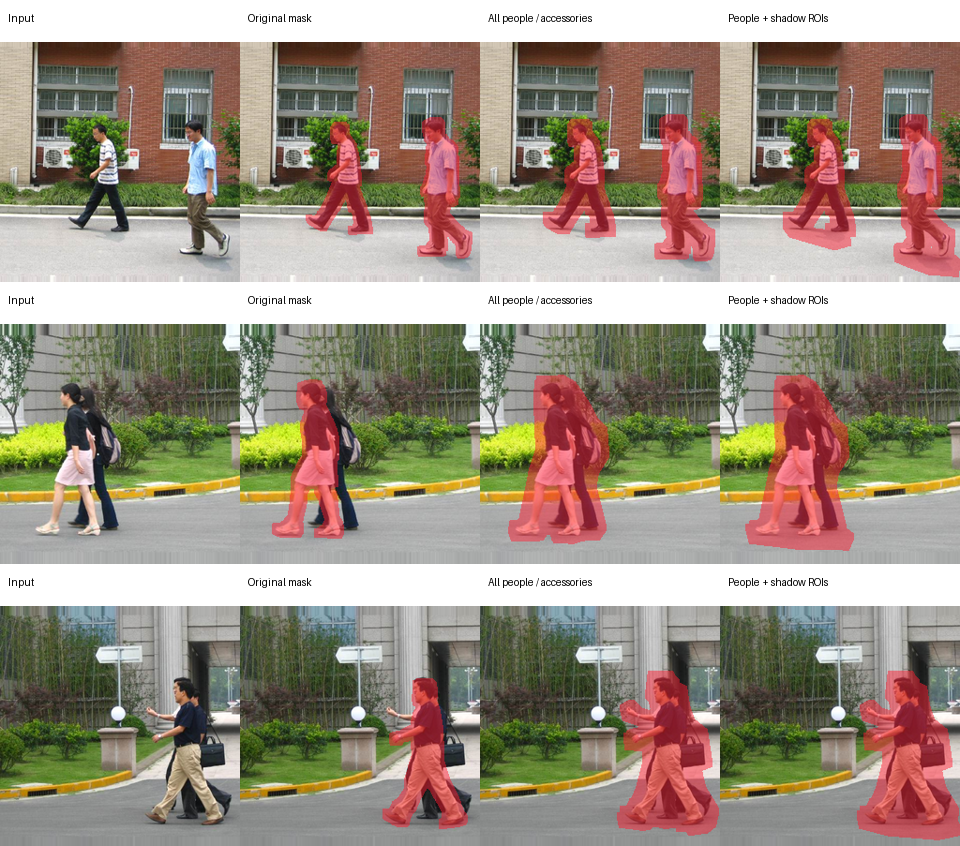

FudanPed00001 {'original': 0.143, 'people_complete': 0.189, 'people_and_shadows': 0.217}
FudanPed00002 {'original': 0.106, 'people_complete': 0.206, 'people_and_shadows': 0.221}
FudanPed00003 {'original': 0.104, 'people_complete': 0.197, 'people_and_shadows': 0.208}


In [7]:
prepared = ROOT / 'data/notebook_run'
records = prepare(source_manifest, annotation_path, prepared, size=SIZE, radius=DILATION_RADIUS)
display(DisplayImage(filename=str(prepared / 'mask_contact_sheet.png')))
for row in records:
    print(row['id'], {k: round(v, 3) for k, v in row['coverage'].items()})


## 4. Define and run the matched diffusion comparison

The pinned SD 1.5 Inpainting checkpoint stays frozen. Each case uses the same initial seed and prompts for all three masks. The negative prompt remains `person, people, human, silhouette, body, artifacts` so mask changes are the experimental variable.

Final compositing preserves pixels outside the active mask exactly. That guarantee does not establish semantic removal quality.

In [8]:
MODEL='stable-diffusion-v1-5/stable-diffusion-inpainting'
REVISION='8a4288a76071f7280aedbdb3253bdb9e9d5d84bb'
NEGATIVE='person, people, human, silhouette, body, artifacts'

def preserve(image,generated,mask):
    return Image.composite(generated.convert('RGB'),image,binary(mask))

def read_data(manifest):
    records=json.loads(manifest.read_text())
    if not records: raise ValueError('Empty manifest')
    for r in records:
        image=Image.open(manifest.parent/r['image']).convert('RGB')
        if image.width!=image.height or image.width%8:raise ValueError('Prepared images must be square and divisible by 8')
        masks={name:binary(Image.open(manifest.parent/r['masks'][name])) for name in VARIANTS}
        arrays={name:np.asarray(m)>0 for name,m in masks.items()}
        for name,m in masks.items():
            if m.size!=image.size or not 0<arrays[name].mean()<1:raise ValueError('Invalid mask')
        if np.any(arrays['original'] & ~arrays['people_complete']):raise ValueError('A correction removed original edit pixels')
        if np.any(arrays['people_complete'] & ~arrays['people_and_shadows']):raise ValueError('Shadow mask must contain the people mask')
    return records


def run_study(manifest, output, hf_home, device='auto', steps=16, guidance=7.5,
              seed=7, seed_offsets=(0,), allow_download=True):
    from types import SimpleNamespace
    a=SimpleNamespace(manifest=Path(manifest), output=Path(output), hf_home=Path(hf_home),
        device=device, steps=steps, guidance=guidance, seed=seed,
        seed_offsets=list(seed_offsets), allow_download=allow_download)
    if steps < 1 or guidance < 0:
        raise ValueError('Invalid sampling settings')
    records=read_data(a.manifest)
    os.environ['HF_HOME']=str(a.hf_home.resolve())
    import torch, diffusers
    from diffusers import StableDiffusionInpaintPipeline,DDIMScheduler
    torch.set_num_threads(min(4,torch.get_num_threads()))
    device=a.device if a.device!='auto' else ('cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu'))
    dtype=torch.float16 if device=='cuda' else torch.float32
    a.output.mkdir(parents=True,exist_ok=True)
    config=dict(model=MODEL,revision=REVISION,device=device,dtype=str(dtype),steps=a.steps,
       guidance=a.guidance,base_seed=a.seed,seed_offsets=a.seed_offsets,negative_prompt=NEGATIVE,
       torch=torch.__version__,diffusers=diffusers.__version__,weights_updated=False,
       manifest_sha256=hashlib.sha256(a.manifest.read_bytes()).hexdigest(),
       annotation_method='manually reviewed person-group regions and approximate shadow edit ROIs')
    (a.output/'config.json').write_text(json.dumps(config,indent=2)+'\n')
    print('Loading the frozen pretrained model on',device,flush=True)
    pipe=StableDiffusionInpaintPipeline.from_pretrained(MODEL,revision=REVISION,torch_dtype=dtype,local_files_only=not a.allow_download)
    pipe.scheduler=DDIMScheduler.from_config(pipe.scheduler.config)
    pipe=pipe.to(device);pipe.enable_attention_slicing()
    pipe.unet.eval().requires_grad_(False);pipe.vae.eval().requires_grad_(False);pipe.text_encoder.eval().requires_grad_(False)
    (a.output/'scheduler.json').write_text(pipe.scheduler.to_json_string())
    rows=[]; overview=[]
    for index,r in enumerate(records):
        image=Image.open(a.manifest.parent/r['image']).convert('RGB')
        masks={name:binary(Image.open(a.manifest.parent/r['masks'][name])) for name in VARIANTS}
        original=np.asarray(masks['original'])>0
        for offset in a.seed_offsets:
            seed=a.seed+index+offset;finals=[]
            folder=a.output/r['id']/f'seed_{seed}';folder.mkdir(parents=True,exist_ok=True)
            for name in VARIANTS:
                mask=masks[name];active=np.asarray(mask)>0
                start=time.perf_counter()
                with torch.inference_mode():
                    result=pipe(prompt=r['prompt'],negative_prompt=NEGATIVE,image=image,mask_image=mask,
                        height=image.height,width=image.width,strength=1.0,num_inference_steps=a.steps,
                        guidance_scale=a.guidance,generator=torch.Generator(device='cpu').manual_seed(seed))
                if result.nsfw_content_detected and any(result.nsfw_content_detected):raise RuntimeError('Safety checker flagged a generated output')
                raw=result.images[0].convert('RGB');final=preserve(image,raw,mask)
                inp=np.asarray(image).astype(float);out=np.asarray(final).astype(float);rawarr=np.asarray(raw).astype(float)
                added=active & ~original
                metric=dict(id=r['id'],variant=name,seed=seed,seconds=time.perf_counter()-start,
                   mask_fraction=float(active.mean()),outside_mask_max_error=float(np.abs(out-inp)[~active].max()),
                   raw_outside_mask_mae=float(np.abs(rawarr-inp)[~active].mean()),
                   added_region_change_mae=float(np.abs(out-inp)[added].mean()) if added.any() else None,
                   mask_sha256=hashlib.sha256(mask.tobytes()).hexdigest(),prompt=r['prompt'])
                if metric['outside_mask_max_error']!=0:raise AssertionError('Unmasked pixels changed')
                raw.save(folder/f'{name}_raw.png');final.save(folder/f'{name}_final.png');mask.save(folder/f'{name}_mask.png')
                rows.append(metric);finals.append(final)
                (a.output/'metrics.json').write_text(json.dumps(rows,indent=2)+'\n')
                print(metric,flush=True)
            sheet([image]+finals,[r['id'],'Original mask','Complete people mask','People + shadow mask'],folder/'comparison.png',tile=256)
            overview.append(Image.open(folder/'comparison.png').copy())
    canvas=Image.new('RGB',(overview[0].width,sum(im.height for im in overview)),'white');y=0
    for im in overview:canvas.paste(im,(0,y));y+=im.height
    canvas.save(a.output/'comparison_contact_sheet.png')
    print('PASS:',len(rows),'matched inference runs. Weights remain unchanged.',flush=True)
    return rows


Loading the frozen pretrained model on mps


model_index.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/748 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

... (27 outputs left out)

  0%|          | 0/16 [00:00<?, ?it/s]

{'id': 'FudanPed00003', 'variant': 'people_complete', 'seed': 9, 'seconds': 2.498301125015132, 'mask_fraction': 0.1969451904296875, 'outside_mask_max_error': 0.0, 'raw_outside_mask_mae': 9.292633339033612, 'added_region_change_mae': 39.25544306553451, 'mask_sha256': 'd4a53ef860b5f91edbf35db4787f733b6112e7f3519f2b2975b47a42c08da5e0', 'prompt': 'an empty outdoor campus walkway, continuous pavement, trees and buildings, no people'}


  0%|          | 0/16 [00:00<?, ?it/s]

{'id': 'FudanPed00003', 'variant': 'people_and_shadows', 'seed': 9, 'seconds': 2.5167668749927543, 'mask_fraction': 0.2078704833984375, 'outside_mask_max_error': 0.0, 'raw_outside_mask_mae': 9.39573260390782, 'added_region_change_mae': 36.191569200779725, 'mask_sha256': 'a9422ea23ce1ac23aad5d10ca6156a3a00639068c83dbeb0c3e584cc14f06033', 'prompt': 'an empty outdoor campus walkway, continuous pavement, trees and buildings, no people'}
PASS: 9 matched inference runs. Weights remain unchanged.


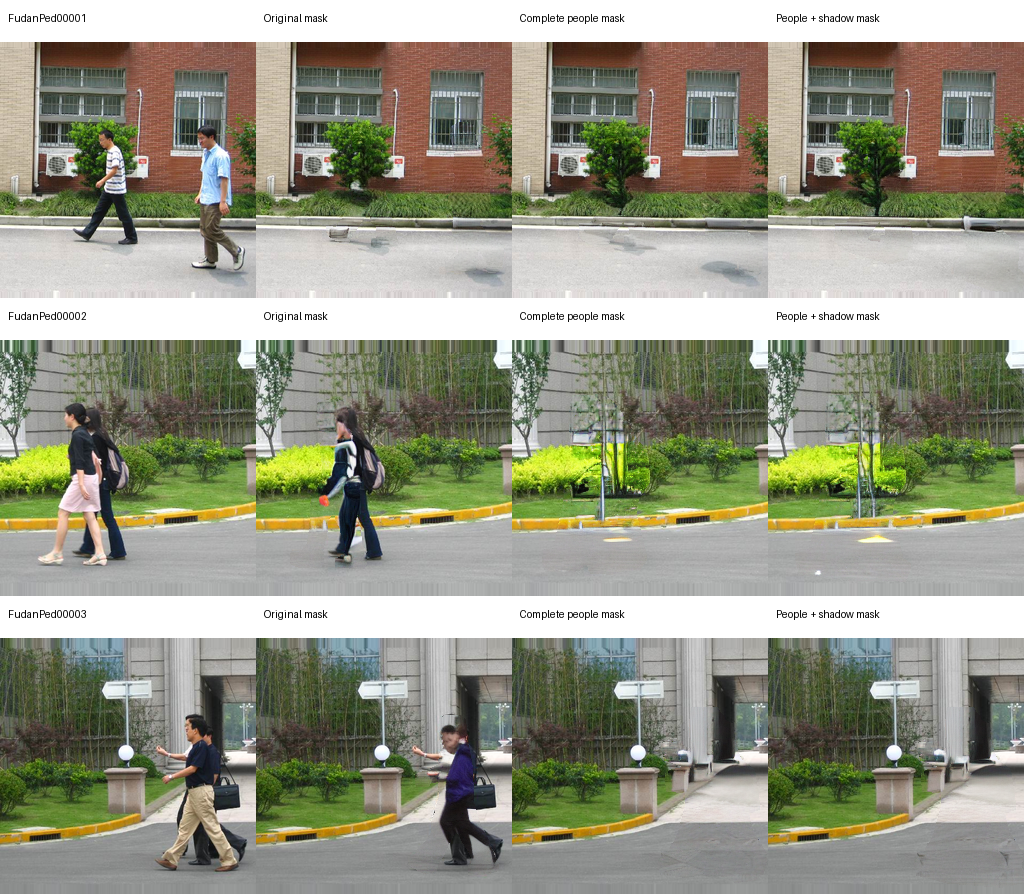

In [9]:
if RUN_MODEL:
    results = run_study(
        prepared / 'manifest.json', OUTPUT, HF_CACHE,
        device=DEVICE, steps=STEPS, guidance=GUIDANCE,
        seed=BASE_SEED, seed_offsets=SEED_OFFSETS,
        allow_download=ALLOW_DOWNLOAD,
    )
    display(DisplayImage(filename=str(OUTPUT / 'comparison_contact_sheet.png')))
else:
    print('Masks prepared. Set RUN_MODEL=True when ready for diffusion inference.')


## 5. Inspect outputs and verify preservation

Check all selected people, bags, and ground shadows. Also check whether generation invents a new object, pole, or road marking and whether curbs/buildings remain coherent. The real photos have no clean hidden-background target, so no reference reconstruction score is available.

In [ ]:
metric_path = OUTPUT / 'metrics.json'
if metric_path.exists():
    results = json.loads(metric_path.read_text())
    assert all(row['outside_mask_max_error'] == 0 for row in results)
    for row in results:
        print(row['id'], row['variant'], 'seed', row['seed'],
              'coverage', round(row['mask_fraction'], 3),
              'outside error', row['outside_mask_max_error'])
else:
    print('No inference results yet.')


## Interpretation

These masks were developed on the same three images. They do not establish performance on unseen scenes. Larger masks may remove people more reliably while damaging more background. Keep failures and compare several seeds and new photographs before selecting a policy. `people_complete` changes coverage, shape and margin together; the next condition separately adds the shadow regions.

To fine-tune weights later, create aligned training targets and compare adapted weights against this corrected-mask baseline. Better masks alone do not produce learned adapters.

Sources: [Penn-Fudan](https://www.cis.upenn.edu/~jshi/ped_html/), [pretrained checkpoint](https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-inpainting), [Diffusers inpainting API](https://huggingface.co/docs/diffusers/v0.35.1/api/pipelines/stable_diffusion/inpaint).